# Explainability and Error Analysis

This notebook looks inside the saved product classifier (TF-IDF 1-2 grams + Logistic Regression, trained and
saved by `baselines/log_regression.ipynb`) to answer three questions:

1. **What has the model learned?** The terms with the largest positive and negative weights for each product.
2. **Why did it make a particular prediction?** Per-complaint term contributions for correct and incorrect examples.
3. **Where and why does it fail?** The most confused product pairs, confidence of right vs. wrong predictions,
   error rate by narrative length and sub-product, and a near-duplicate leakage check.

Everything is evaluated on the held-out **test** split; nothing is re-trained here.

In [1]:
import textwrap
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score

In [2]:
RANDOM_STATE = 42

DATA_PATH = Path("../data/processed/complaint_router_modeling_data.csv")
MODEL_PATH = Path("../models/product_logreg.joblib")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SHORT_LABELS = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan",
}

pd.set_option("display.max_colwidth", None)

## 1. Load Data and the Saved Model

The processed dataset carries a fixed `split` column (80/20, stratified on Product), so the test complaints here
are exactly the ones the Logistic Regression notebook was evaluated on.

In [3]:
# Load only the columns this notebook needs (keeps memory low)
columns = ["Complaint ID", "Product", "Sub-product", "Issue", "Consumer complaint narrative", "clean_narrative", "split"]
df = pd.read_csv(DATA_PATH, usecols=columns)

train = df.loc[df["split"] == "train", ["Product", "clean_narrative"]].copy()  # train is only used for the leakage check
test = df[df["split"] == "test"].copy()
del df

print(f"Training samples: {len(train):,}")
print(f"Testing samples: {len(test):,}")
print("Number of classes:", test["Product"].nunique())

Training samples: 130,000
Testing samples: 32,500
Number of classes: 11


In [4]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Saved model not found at {MODEL_PATH.resolve()}.\n"
        "Run notebooks/baselines/log_regression.ipynb first: it trains the product Logistic Regression "
        "pipeline and saves it to models/product_logreg.joblib."
    )

pipeline = joblib.load(MODEL_PATH)
tfidf = pipeline.named_steps["tfidf"]
clf = pipeline.named_steps["clf"]

feature_names = tfidf.get_feature_names_out()
classes = clf.classes_
coef = clf.coef_  # shape: (n_classes, n_features)

print(pipeline)
print(f"Vocabulary size: {len(feature_names):,}")
print("Coefficient matrix shape:", coef.shape)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.9, max_features=100000, min_df=5,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('clf', LogisticRegression(C=4, max_iter=2000))])
Vocabulary size: 100,000
Coefficient matrix shape: (11, 100000)


### Test-Set Predictions

Predictions are computed once and reused in every section below. The scores should match the Logistic Regression
notebook.

In [5]:
X_test = tfidf.transform(test["clean_narrative"])
test_proba = clf.predict_proba(X_test)

class_index = {label: i for i, label in enumerate(classes)}

test["predicted"] = classes[test_proba.argmax(axis=1)]
test["confidence"] = test_proba.max(axis=1)
test["actual_proba"] = test_proba[np.arange(len(test)), test["Product"].map(class_index).to_numpy()]
test["correct"] = test["predicted"] == test["Product"]

print(f"Test accuracy: {accuracy_score(test['Product'], test['predicted']):.4f}")
print(f"Test macro-F1: {f1_score(test['Product'], test['predicted'], average='macro'):.4f}")
print(f"Misclassified test complaints: {(~test['correct']).sum():,}")

Test accuracy: 0.7978
Test macro-F1: 0.7760
Misclassified test complaints: 6,571


## 2. Global Explanations: Which Terms Drive Each Product?

Logistic Regression learns one weight per (term, product). A large **positive** coefficient means the term pushes
a complaint *toward* that product; a large **negative** coefficient pushes it *away*.

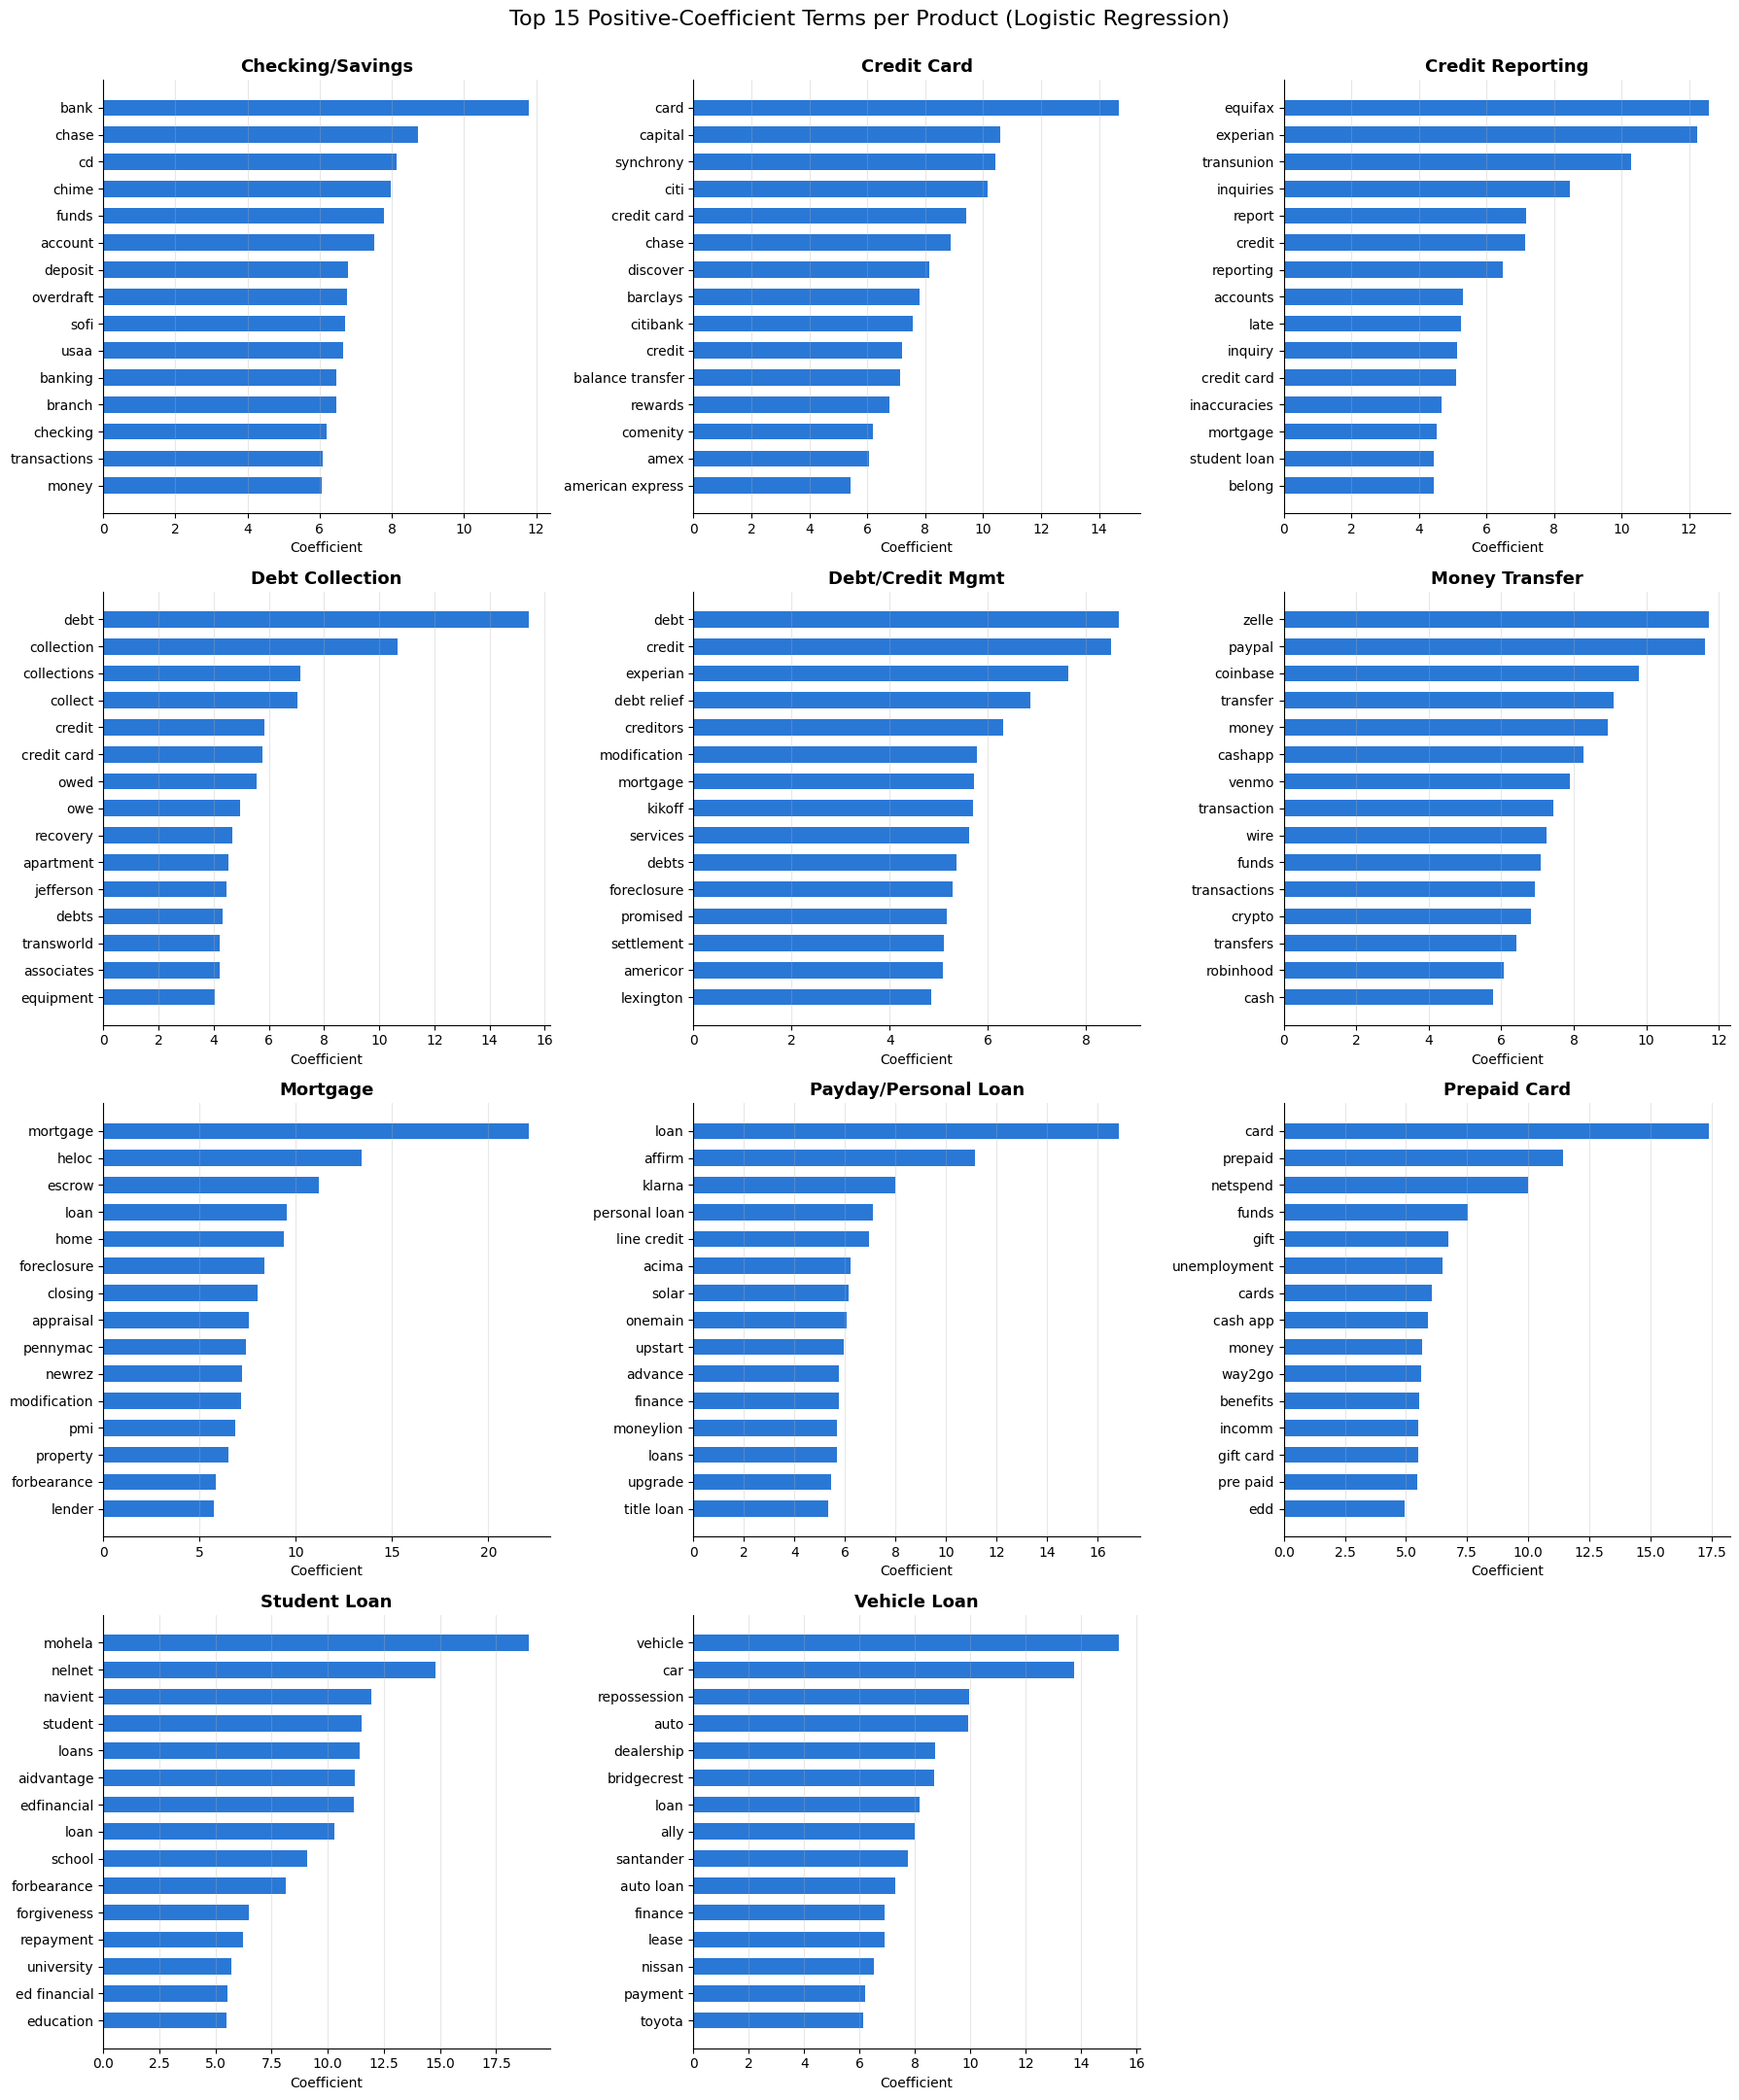

In [6]:
TOP_N = 15

fig, axes = plt.subplots(4, 3, figsize=(18, 22))

for i, ax in enumerate(axes.flat[: len(classes)]):
    top = np.argsort(coef[i])[::-1][:TOP_N]
    ax.barh(feature_names[top][::-1], coef[i, top][::-1], color="#2a78d6", height=0.6)
    ax.set_title(SHORT_LABELS[classes[i]], fontsize=13, fontweight="bold")
    ax.set_xlabel("Coefficient")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(classes):]:
    ax.axis("off")  # 11 classes in a 4x3 grid

fig.suptitle(f"Top {TOP_N} Positive-Coefficient Terms per Product (Logistic Regression)", fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.savefig(FIGURES_DIR / "explainability_top_terms_per_class.png", dpi=300, bbox_inches="tight")
plt.show()

### Top Negative Terms

The most negative coefficients show which terms the model treats as evidence *against* each product.

In [7]:
negative_terms = pd.DataFrame(
    {
        "Product": [SHORT_LABELS[c] for c in classes],
        "Top 10 negative terms": [
            ", ".join(feature_names[np.argsort(coef[i])[:10]]) for i in range(len(classes))
        ],
    }
).set_index("Product")

display(negative_terms)

,Top 10 negative terms
Product,
Checking/Savings,"loan, credit, payment, debt, credit card, payments, payoff, experian, prepaid, credit report"
Credit Card,"loan, funds, mortgage, lease, loans, debit, vehicle, gift card, employer, debit card"
Credit Reporting,"money, refund, funds, bank, sincerely, fees, charges, transaction, chime, paypal"
Debt Collection,"denied, chime, customer, app, funds, bank, money, transactions, refund, missing"
Debt/Credit Mgmt,"attached, account number, hours, citibank, declined, transfer, bank, information regarding, unable, kindly"
Money Transfer,"credit, loan, debt, late, removed, card, owe, reporting, collection, loans"
Mortgage,"card, account, car, vehicle, dispute, accounts, student, transaction, debt, auto loan"
Payday/Personal Loan,"mortgage, student, card, chase, capital, student loan, auto loan, bank america, forbearance, mohela"
Prepaid Card,"credit, credit card, loan, chase, debt, capital, payment, payments, fargo, wells fargo"


## 3. Local Explanations: Why This Prediction?

For one complaint, the model's score for product *k* is `intercept_k + sum(tfidf(term) * coef_k(term))`. Each term's
**contribution** `tfidf * coef` therefore shows how much that word moved the complaint toward a product. Only terms
that actually appear in the complaint (non-zero TF-IDF) can contribute.

In [8]:
def explain_complaint(clean_text, top_n=10, for_class=None):
    # Returns the predicted product, the top-3 probabilities, and the terms with the largest
    # contributions toward `for_class` (default: the predicted product).
    x = tfidf.transform([clean_text])
    proba = clf.predict_proba(x)[0]
    ranked = np.argsort(proba)[::-1]
    predicted = classes[ranked[0]]
    k = class_index[for_class] if for_class is not None else ranked[0]

    term_idx, tfidf_values = x.indices, x.data
    contributions = tfidf_values * coef[k, term_idx]
    order = np.argsort(contributions)[::-1][:top_n]

    top_terms = pd.DataFrame(
        {
            "term": feature_names[term_idx[order]],
            "tfidf": tfidf_values[order],
            "coefficient": coef[k, term_idx[order]],
            "contribution": contributions[order],
        }
    )
    top3 = [(classes[i], proba[i]) for i in ranked[:3]]
    return predicted, top3, top_terms

In [9]:
def truncate(text, max_chars=600):
    text = " ".join(str(text).split())
    return text if len(text) <= max_chars else text[:max_chars].rsplit(" ", 1)[0] + " ..."


def show_explanation(row, top_n=10):
    predicted, top3, top_terms = explain_complaint(row["clean_narrative"], top_n=top_n)
    print(f"Complaint ID: {row['Complaint ID']}")
    print(f"Actual product:    {row['Product']}")
    print(f"Predicted product: {predicted}")
    print("Top-3 probabilities: " + " | ".join(f"{SHORT_LABELS[c]} {p:.2f}" for c, p in top3))
    print()
    print(textwrap.fill(truncate(row["Consumer complaint narrative"]), width=110))
    print(f"\nTop terms pushing toward the predicted product ({SHORT_LABELS[predicted]}):")
    display(top_terms.round(3))
    if predicted != row["Product"]:
        _, _, actual_terms = explain_complaint(row["clean_narrative"], top_n=top_n, for_class=row["Product"])
        print(f"Top terms pushing toward the actual product ({SHORT_LABELS[row['Product']]}):")
        display(actual_terms.round(3))
    print("-" * 110)

In [10]:
# Pick moderately short narratives so the printed text is readable
readable = test[test["Consumer complaint narrative"].str.len().between(300, 1200)]

correct_examples = readable[readable["correct"]].sample(2, random_state=RANDOM_STATE)
incorrect_examples = readable[~readable["correct"]].sample(2, random_state=RANDOM_STATE)

### Correctly Classified Examples

In [11]:
for _, row in correct_examples.iterrows():
    show_explanation(row)

Complaint ID: 11758472
Actual product:    Credit reporting or other personal consumer reports
Predicted product: Credit reporting or other personal consumer reports
Top-3 probabilities: Credit Reporting 0.81 | Debt Collection 0.10 | Credit Card 0.05

I am writing to dispute the accuracy and legitimacy of several hard inquiries listed on my credit report. Upon
reviewing my credit report, I have identified the following inquiries, which I believe were unauthorized and
made without my consent : XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX
XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXX XXXXXX/XX/XXXX According to 15 U.S. Code 1681
( Fair Credit Reporting Act ), you are required to ensure that the information contained in my credit report
is accurate, complete, and verifiable. Hard ...

Top terms pushing toward the predicted product (Credit Reporting):


,term,tfidf,coefficient,contribution
0,inquiries,0.144,8.474,1.218
1,report,0.078,7.161,0.558
2,credit,0.076,7.137,0.541
3,reporting,0.062,6.477,0.402
4,credit report,0.094,2.446,0.229
5,remove,0.052,3.519,0.182
6,ensure information,0.104,1.458,0.152
7,explicit authorization,0.130,1.121,0.145
8,following,0.046,3.129,0.145
9,failure investigate,0.104,1.346,0.140


--------------------------------------------------------------------------------------------------------------
Complaint ID: 12214047
Actual product:    Debt collection
Predicted product: Debt collection
Top-3 probabilities: Debt Collection 0.91 | Debt/Credit Mgmt 0.03 | Payday/Personal Loan 0.02

Oliphant LLC repeatedly lied to me about the date of first delinquency. They stated it was XX/XX/year>, but it
was actually XX/XX/year>. Company also repeatedly called my phone number after I asked them to remove me from
the list. When I spoke with the company, they lied and stated that that the account was in-statute and
collectible, when it wasn't, due to being time-barred due to a 4 year collection statute.

Top terms pushing toward the predicted product (Debt Collection):


,term,tfidf,coefficient,contribution
0,collection,0.081,10.649,0.858
1,llc,0.119,4.018,0.477
2,oliphant,0.248,1.685,0.418
3,repeatedly,0.187,2.188,0.410
4,date delinquency,0.162,1.962,0.318
5,company,0.113,2.313,0.261
6,asked remove,0.199,1.279,0.254
7,time barred,0.193,1.209,0.233
8,barred,0.184,1.097,0.201
9,repeatedly called,0.206,0.866,0.178


--------------------------------------------------------------------------------------------------------------


### Misclassified Examples

For mistakes, the terms toward the predicted product show what misled the model, and the terms toward the actual
product show the (weaker) evidence it had for the right answer.

In [12]:
for _, row in incorrect_examples.iterrows():
    show_explanation(row)

Complaint ID: 21701019
Actual product:    Checking or savings account
Predicted product: Credit card
Top-3 probabilities: Credit Card 0.85 | Checking/Savings 0.14 | Prepaid Card 0.00

Capital One Dispute Reconsideration Request Claim # XXXX I am filing a complaint regarding Capital Ones
handling of a dispute that was incorrectly classified and ultimately denied. In XXXX, I disputed a charge that
was made using my card information without my authorization. This was not a standard billing dispute it was
unauthorized use of my card. Although I was previously associated with the individual who made the charge,
they no longer had permission to use my card, and my payment information was supposed to be removed from the
account. The account holder failed to remove my card, and ...

Top terms pushing toward the predicted product (Credit Card):


,term,tfidf,coefficient,contribution
0,capital,0.139,10.587,1.471
1,card,0.086,14.682,1.264
2,merchant,0.106,5.396,0.570
3,charge,0.077,4.341,0.333
4,use card,0.130,2.508,0.327
5,capital ones,0.093,3.011,0.281
6,dispute,0.084,3.116,0.263
7,disputed charge,0.087,2.494,0.218
8,charges,0.048,4.129,0.198
9,billing dispute,0.096,2.012,0.194


Top terms pushing toward the actual product (Checking/Savings):


,term,tfidf,coefficient,contribution
0,capital,0.139,4.905,0.681
1,merchant,0.106,4.011,0.423
2,temporary credit,0.093,3.978,0.369
3,claim,0.095,3.400,0.323
4,transaction,0.079,3.897,0.310
5,denied,0.082,3.503,0.287
6,account,0.037,7.499,0.275
7,capital denied,0.113,1.885,0.213
8,use card,0.130,1.446,0.188
9,unauthorized,0.082,2.159,0.177


--------------------------------------------------------------------------------------------------------------
Complaint ID: 21176585
Actual product:    Debt collection
Predicted product: Credit reporting or other personal consumer reports
Top-3 probabilities: Credit Reporting 0.76 | Credit Card 0.16 | Debt Collection 0.05

I am disputing one or more accounts that are inaccurately reporting on my XXXX and TransUnion credit reports.
My personal information was compromised in a data breach, and as a result, fraudulent accounts were opened in
my name. I have filed an Identity Theft Report with the Federal Trade Commission and have attached the
documentation as supporting evidence. I have never applied for, authorized, or benefited from these accounts.
Pursuant to the Fair Credit Reporting Act ( 15 U.S.C. 1681c-2 ), I respectfully request the immediate blocking
and permanent removal of these accounts, cessation of ...

Top terms pushing toward the predicted product (Credit Reporting):


,term,tfidf,coefficient,contribution
0,transunion,0.084,10.270,0.860
1,accounts,0.126,5.313,0.671
2,reporting,0.096,6.477,0.620
3,credit,0.054,7.137,0.387
4,reporting transunion,0.159,1.869,0.298
5,report,0.041,7.161,0.291
6,attached,0.070,3.382,0.236
7,reports,0.070,3.376,0.235
8,removal,0.078,2.544,0.200
9,fraudulent,0.061,2.791,0.169


Top terms pushing toward the actual product (Debt Collection):


,term,tfidf,coefficient,contribution
0,credit,0.054,5.854,0.318
1,fraudulent accounts,0.095,3.154,0.299
2,result fraudulent,0.148,1.832,0.270
3,disputing,0.083,2.670,0.223
4,reporting,0.096,1.868,0.179
5,act 15,0.097,1.574,0.152
6,theft,0.068,2.080,0.141
7,accounts,0.126,1.096,0.138
8,written,0.060,2.226,0.134
9,data breach,0.099,1.294,0.128


--------------------------------------------------------------------------------------------------------------


## 4. Error Analysis on the Test Set

### 4.1 Most Confused Product Pairs

In [13]:
errors = test[~test["correct"]]
class_sizes = test["Product"].value_counts()

pair_counts = errors.groupby(["Product", "predicted"]).size().sort_values(ascending=False)
top_pairs = pair_counts.head(10)

confused_table = pd.DataFrame(
    {
        "actual": [SHORT_LABELS[a] for a, _ in top_pairs.index],
        "predicted": [SHORT_LABELS[p] for _, p in top_pairs.index],
        "errors": top_pairs.to_numpy(),
        "% of actual class": [100 * n / class_sizes[a] for (a, _), n in top_pairs.items()],
        "% of all errors": 100 * top_pairs.to_numpy() / len(errors),
    },
    index=range(1, len(top_pairs) + 1),
)

display(confused_table.round(1))
print(f"The top 10 pairs account for {100 * top_pairs.sum() / len(errors):.1f}% of all {len(errors):,} errors.")

,actual,predicted,errors,% of actual class,% of all errors
1,Debt Collection,Credit Reporting,672,13.4,10.2
2,Credit Reporting,Debt Collection,502,7.2,7.6
3,Money Transfer,Checking/Savings,478,15.9,7.3
4,Checking/Savings,Money Transfer,387,9.7,5.9
5,Credit Card,Credit Reporting,253,6.3,3.9
6,Debt/Credit Mgmt,Debt Collection,231,23.1,3.5
7,Credit Card,Checking/Savings,231,5.8,3.5
8,Checking/Savings,Credit Card,205,5.1,3.1
9,Credit Reporting,Credit Card,183,2.6,2.8
10,Prepaid Card,Checking/Savings,158,15.8,2.4


The top 10 pairs account for 50.2% of all 6,571 errors.


### 4.2 Sample Misclassified Narratives (Top 3 Pairs)

In [14]:
for actual, predicted in top_pairs.index[:3]:
    print("=" * 110)
    print(f"ACTUAL: {SHORT_LABELS[actual]}  ->  PREDICTED: {SHORT_LABELS[predicted]}")
    print("=" * 110)
    pair_rows = errors[(errors["Product"] == actual) & (errors["predicted"] == predicted)]
    for _, row in pair_rows.sample(2, random_state=RANDOM_STATE).iterrows():
        print(f"\nComplaint ID {row['Complaint ID']} | Sub-product: {row['Sub-product']} | Issue: {row['Issue']}")
        print(f"P(predicted) = {row['confidence']:.2f}   P(actual) = {row['actual_proba']:.2f}")
        print(textwrap.fill(truncate(row["Consumer complaint narrative"]), width=110))
    print()

ACTUAL: Debt Collection  ->  PREDICTED: Credit Reporting

Complaint ID 12069893 | Sub-product: I do not know | Issue: Attempts to collect debt not owed
P(predicted) = 0.72   P(actual) = 0.20
Social Security is reported inaccurate things on my credit report and my information was leaked and the data
breach XXXX XXXX XXXX XXXX XXXX XXXX was paid but reporting as negative XXXX XXXX XXXXXXXX XXXX XXXX is

Complaint ID 18204835 | Sub-product: I do not know | Issue: False statements or representation
P(predicted) = 0.43   P(actual) = 0.40
I want this account on my credit report to be investigated.

ACTUAL: Credit Reporting  ->  PREDICTED: Debt Collection

Complaint ID 8346909 | Sub-product: Credit reporting | Issue: Problem with a company's investigation into an existing problem
P(predicted) = 0.44   P(actual) = 0.43
I requested that Experian tell me their method of verification for PHEAA acct including phone number and
address of verifying party and name of person they spoke to the allegedl

### 4.3 Confidence of Correct vs. Incorrect Predictions

The maximum class probability acts as a confidence score. If wrong predictions are mostly low-confidence, a
router could send low-confidence complaints to a human reviewer instead of routing them automatically.

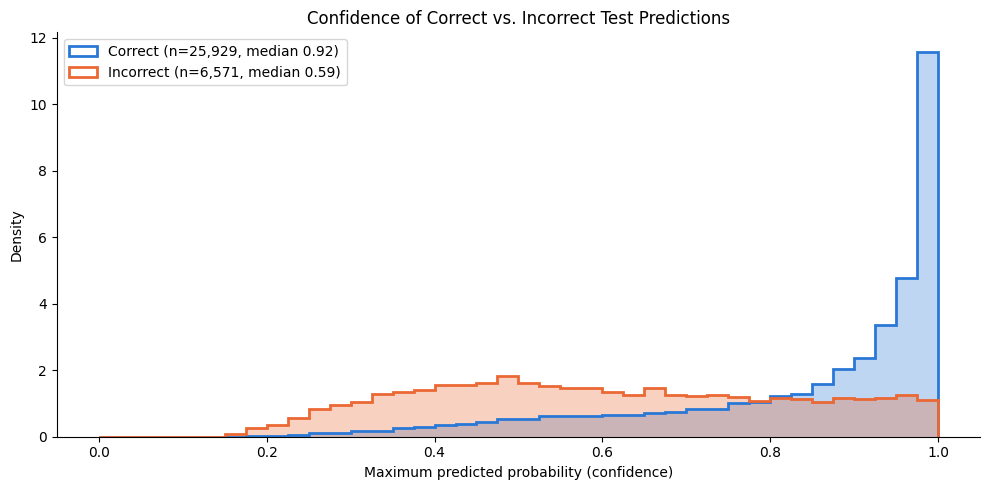

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, 1, 41)

for is_correct, color, label in [(True, "#2a78d6", "Correct"), (False, "#eb6834", "Incorrect")]:
    values = test.loc[test["correct"] == is_correct, "confidence"]
    ax.hist(values, bins=bins, density=True, histtype="stepfilled", alpha=0.3, color=color)
    ax.hist(
        values, bins=bins, density=True, histtype="step", linewidth=2, color=color,
        label=f"{label} (n={len(values):,}, median {values.median():.2f})",
    )

ax.set_xlabel("Maximum predicted probability (confidence)")
ax.set_ylabel("Density")
ax.set_title("Confidence of Correct vs. Incorrect Test Predictions")
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "error_confidence_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
confidence_bucket = pd.cut(test["confidence"], bins=[0, 0.5, 0.7, 0.9, 1.0], include_lowest=True)

confidence_table = test.groupby(confidence_bucket, observed=True).agg(
    complaints=("correct", "size"),
    accuracy=("correct", "mean"),
)
confidence_table["% of test set"] = 100 * confidence_table["complaints"] / len(test)
confidence_table.index.name = "confidence"

display(confidence_table.round(3))

,complaints,accuracy,% of test set
confidence,,,
"(-0.001, 0.5]",4300,0.438,13.231
"(0.5, 0.7]",5218,0.641,16.055
"(0.7, 0.9]",7893,0.807,24.286
"(0.9, 1.0]",15089,0.949,46.428


### 4.4 Error Rate by Narrative Length

Length is measured in words of the cleaned narrative.

In [17]:
test["word_count"] = test["clean_narrative"].str.split().str.len()

length_bins = [0, 50, 100, 200, 400, 800, np.inf]
length_labels = ["<50", "50-99", "100-199", "200-399", "400-799", "800+"]
test["length_bucket"] = pd.cut(test["word_count"], bins=length_bins, labels=length_labels, right=False)

length_table = test.groupby("length_bucket", observed=True).agg(
    complaints=("correct", "size"),
    error_rate=("correct", lambda s: 1 - s.mean()),
    median_confidence=("confidence", "median"),
)
length_table.index.name = "words"

display(length_table.round(3))

,complaints,error_rate,median_confidence
words,,,
<50,4673,0.316,0.768
50-99,6207,0.216,0.862
100-199,9741,0.181,0.896
200-399,8240,0.170,0.902
400-799,2908,0.163,0.915
800+,731,0.168,0.924


### 4.5 Money Transfer vs. Checking/Savings: Error Rate by Sub-product

Money Transfer and Checking/Savings complaints often describe the same events (Zelle payments, bank transfers,
frozen funds). Breaking the errors down by the CFPB **Sub-product** shows where the overlap comes from. Only
sub-products with at least 30 test complaints are shown.

In [18]:
MONEY_TRANSFER = "Money transfer, virtual currency, or money service"
CHECKING = "Checking or savings account"


def subproduct_errors(actual, other, min_count=30):
    rows = test[test["Product"] == actual]
    table = rows.groupby("Sub-product").agg(
        complaints=("correct", "size"),
        error_rate=("correct", lambda s: 1 - s.mean()),
        predicted_as_other=("predicted", lambda s: (s == other).mean()),
    )
    table = table[table["complaints"] >= min_count].sort_values("complaints", ascending=False)
    return table.rename(columns={"predicted_as_other": f"share predicted {SHORT_LABELS[other]}"})


print("Actual Money Transfer complaints:")
display(subproduct_errors(MONEY_TRANSFER, CHECKING).round(3))

print("Actual Checking/Savings complaints:")
display(subproduct_errors(CHECKING, MONEY_TRANSFER).round(3))

Actual Money Transfer complaints:


,complaints,error_rate,share predicted Checking/Savings
Sub-product,,,
Domestic (US) money transfer,1331,0.142,0.104
Mobile or digital wallet,1009,0.281,0.206
Virtual currency,373,0.196,0.142
International money transfer,157,0.115,0.064
"Money order, traveler's check or cashier's check",66,0.667,0.591
Check cashing service,43,0.767,0.605


Actual Checking/Savings complaints:


,complaints,error_rate,share predicted Money Transfer
Sub-product,,,
Checking account,3281,0.175,0.087
Other banking product or service,344,0.390,0.238
Savings account,323,0.121,0.059
CD (Certificate of Deposit),52,0.154,0.038


## 5. Near-Duplicate Leakage Check

The cleaning notebook removed exact duplicate narratives, but near-duplicates (for example, the same template
dispute letter submitted many times with small edits) can still appear in both train and test. If the model were
memorizing those, test scores would be inflated. We hash the first 200 characters of each cleaned narrative, flag
test complaints whose prefix also appears in the training set, and compare scores on flagged vs. unflagged test
complaints.

In [19]:
PREFIX_CHARS = 200


def prefix_hashes(texts):
    return pd.util.hash_pandas_object(texts.str[:PREFIX_CHARS], index=False).to_numpy()


train_hashes = prefix_hashes(train["clean_narrative"])
test_hashes = prefix_hashes(test["clean_narrative"])
test["prefix_in_train"] = np.isin(test_hashes, train_hashes)

# Does a training complaint with the same prefix also carry the same product label?
train_pairs = set(zip(train_hashes, train["Product"]))
test["prefix_label_in_train"] = [(h, p) in train_pairs for h, p in zip(test_hashes, test["Product"])]

matched = test["prefix_in_train"]
print(f"Test complaints whose first {PREFIX_CHARS} characters appear in train: {matched.sum():,} ({matched.mean():.1%})")
print(f"...of those, a train match has the same product: {test.loc[matched, 'prefix_label_in_train'].mean():.1%}")

Test complaints whose first 200 characters appear in train: 1,818 (5.6%)
...of those, a train match has the same product: 97.2%


In [20]:
def subset_scores(name, rows):
    return {
        "test subset": name,
        "complaints": len(rows),
        "accuracy": accuracy_score(rows["Product"], rows["predicted"]),
        "macro-F1": f1_score(rows["Product"], rows["predicted"], average="macro", zero_division=0),
    }


leakage_table = pd.DataFrame(
    [
        subset_scores("prefix seen in train", test[matched]),
        subset_scores("no prefix match", test[~matched]),
        subset_scores("all test", test),
    ]
).set_index("test subset")

display(leakage_table.round(4))

,complaints,accuracy,macro-F1
test subset,,,
prefix seen in train,1818,0.9571,0.7295
no prefix match,30682,0.7884,0.7707
all test,32500,0.7978,0.7760


Prefix matches are not spread evenly across products, so the class mix of the two subsets differs. The tables below
show which products have the most matches and the most common matched openings.

In [21]:
match_by_product = test.groupby("Product").agg(
    complaints=("prefix_in_train", "size"),
    prefix_match_rate=("prefix_in_train", "mean"),
)
match_by_product.index = match_by_product.index.map(SHORT_LABELS)
display(match_by_product.sort_values("prefix_match_rate", ascending=False).round(3))

print("Most common matched openings (first 120 characters):")
display(test.loc[matched, "clean_narrative"].str[:120].value_counts().head(5).to_frame("test complaints"))

,complaints,prefix_match_rate
Product,,
Credit Reporting,7000,0.169
Money Transfer,3000,0.119
Debt Collection,5000,0.024
Student Loan,2000,0.014
Checking/Savings,4000,0.013
Debt/Credit Mgmt,1000,0.013
Credit Card,4000,0.009
Vehicle Loan,2000,0.008
Payday/Personal Loan,1500,0.007


Most common matched openings (first 120 characters):


,test complaints
clean_narrative,
"i am filing a complaint against cash app ( block , inc. ) due to inadequate customer service and unfair practices, which",132
in accordance with the fair credit reporting act. the list of accounts below has violated my federally protected consume,82
"i am writing to formally express my concerns regarding zelle 's handling of disputes, particularly in light of the recen",39
"this cfpb complaint has been filed to request pursuant to fcra 605b ( 15 u.s.c. 1681c-2 ) that you, the experian credit",35
"i am filing a complaint against cash app ( block , inc ) due to inadequate customer service and unfair practices, which",34


## 6. Findings

The saved Logistic Regression model (C = 4) reproduces its notebook scores on the 32,500 test complaints: **accuracy 0.798, macro-F1 0.776** (6,571 errors).

- **What the model learned: company names matter a lot.** The strongest positive terms are often company names rather than descriptions of the problem: Equifax / Experian / TransUnion (Credit Reporting), MOHELA / Nelnet / Navient / Aidvantage (Student Loan), Zelle / PayPal / Coinbase / Cash App / Venmo (Money Transfer), Capital One / Synchrony / Citi / Discover (Credit Card), Bridgecrest / Ally / Santander (Vehicle Loan), Affirm / Klarna / OneMain (Payday/Personal Loan). These are legitimate routing signals, because a company largely determines the product. The downside is that the model partly learns *who* the complaint is about rather than *what* happened. That works poorly for multi-product banks (Chase is a top term for both Checking/Savings and Credit Card) and for companies not seen in training. The negative terms mirror this: words like *money, refund, funds, bank* count against Credit Reporting, and *credit, loan, debt* count against Money Transfer.
- **Local explanations** show the same pattern. Correct predictions rest on topical words (*inquiries*, *collection*, *date delinquency*) plus company names (*Oliphant*). In both misclassified examples, a company name pulled the complaint to the wrong product. A Capital One dispute filed under Checking/Savings was predicted Credit Card (0.85) because of *capital*, *card* and *merchant*. A Debt Collection complaint about identity-theft accounts was predicted Credit Reporting (0.76) because of *TransUnion* and *reporting*.
- **Most confused pairs.** The top 10 pairs account for 50.2% of all errors. Two symmetric pairs alone account for 31%:
  - Debt Collection → Credit Reporting: 672 (13.4% of Debt Collection)
  - Credit Reporting → Debt Collection: 502 (7.2%)
  - Money Transfer → Checking/Savings: 478 (15.9% of Money Transfer)
  - Checking/Savings → Money Transfer: 387 (9.7%)

  Relative to class size, the worst confusion is Debt/Credit Mgmt → Debt Collection (23.1% of that class), followed by Money Transfer → Checking/Savings (15.9%) and Prepaid Card → Checking/Savings (15.8%). Many of these errors are label ambiguity rather than model failure. For example, one complaint filed as Debt Collection reads in full "I want this account on my credit report to be investigated." The consumer chooses the product when filing, and the same event can reasonably fit two categories.
- **Confidence.** Correct predictions have a median confidence of **0.92**; incorrect ones **0.59**. Predictions above 0.9 cover 46% of the test set and are 94.9% accurate. Predictions at or below 0.5 (13% of the test set) are only 43.8% accurate. Sending everything with confidence ≤ 0.7 to a human reviewer would cover 29% of complaints and catch about 65% of the errors, which is a practical design for a real router.
- **Narrative length.** Short narratives are much harder. Complaints under 50 words have a 31.6% error rate, compared with 21.6% for 50–99 words and 16–18% for 100+ words. Short texts give the model fewer clues and are more often vague.
- **Money Transfer vs. Checking/Savings by Sub-product:**
  - Money Transfer errors concentrate in cash-like sub-products: *Check cashing service* has 76.7% error and *Money order, traveler's check or cashier's check* has 66.7% error, with about 60% of each predicted as Checking/Savings. *Mobile or digital wallet* has 28.1% error, against 14.2% for domestic and 11.5% for international transfers.
  - On the Checking side, *Other banking product or service* has 39.0% error (23.8% predicted Money Transfer), compared with 17.5% for checking accounts and 12.1% for savings.
  - These sub-products describe the same bank-side events, such as Zelle sent from a checking account or a bank cashier's check.
- **Near-duplicate leakage check.** 1,818 test complaints (**5.6%**) share their first 200 characters with a training complaint. This matches the 5.59% measured in the cleaning notebook, and 97.2% of those matches have the same product. The matches concentrate in Credit Reporting (16.9% of its test rows: FCRA dispute and §605B identity-theft templates) and Money Transfer (11.9%: the Cash App and Zelle template campaigns).
  - Accuracy is much higher on matched rows (0.957 vs. 0.788).
  - Macro-F1 is actually lower on matched rows (0.730 vs. 0.771). This is unreliable, because about 85% of the matched subset is Credit Reporting or Money Transfer, and the other classes have only a handful of matched rows each.
  - What matters is the headline: **removing the matched rows lowers test macro-F1 only from 0.776 to 0.771, and accuracy from 0.798 to 0.788.** Near-duplicates inflate the reported results only slightly, and the model comparison is not driven by memorized templates.